![Banner](../images/09_06_banner_rs_lidar.png)


# Buildings and Urban Features from LiDAR

Roofs are flat or planar, solid and high above the ground, while trees are rough, porous and produce several returns per pulse. These differences let LiDAR separate buildings from vegetation, outline footprints, measure heights and roof shapes, and estimate how much sunlight each roof receives. This notebook does all of that with `geolattice.rsense.lidar` on the Autzen Stadium area in Eugene, Oregon, where the producer labelled building points, and then applies the label-free workflow to the 2008 survey of the University at Buffalo North Campus.


## Overview

### Urban applications of LiDAR

- **3D city models** for planning, visualisation, noise and wind simulation, and digital twins. The CityGML standard defines levels of detail: LoD1 extrudes each footprint to one height (block model), LoD2 adds roof shapes, LoD3 adds facade detail.
- **Building inventories** for property tax, population and energy models, and post-disaster damage assessment (comparing surveys before and after an earthquake or tornado).
- **Solar potential** of roofs from their slope, aspect and shading by neighbouring buildings and trees.
- **Infrastructure**: power-line clearance and vegetation encroachment, road surfaces and kerbs, bridges, street furniture and urban tree inventories.
- **Flood and drainage** modelling, which needs buildings as obstacles and accurate street-level terrain.

### How buildings differ from trees in a point cloud

| Property | Roof | Tree crown |
|---|---|---|
| Local geometry | Planar: neighbours lie on a plane; the smallest eigenvalue of their covariance is near zero | Volumetric: points scatter in 3D |
| Returns per pulse | Mostly one (the roof is solid) | Several (pulses pass through gaps) |
| Height above ground | Uniform over the roof | Varies, peaks at the treetop |
| Object shape | Straight edges, right angles, large flat patches | Round, irregular |

**Eigenvalue features.** For the $k$ nearest neighbours of a point, the covariance matrix has eigenvalues $\lambda_1 \ge \lambda_2 \ge \lambda_3$. Normalised combinations describe the local shape: **linearity** $(\lambda_1 - \lambda_2)/\lambda_1$ (wires, edges), **planarity** $(\lambda_2 - \lambda_3)/\lambda_1$ (roofs, ground, walls), **scattering** $\lambda_3/\lambda_1$ (vegetation), and **verticality** $1 - |n_z|$ from the normal vector (walls).

**RANSAC planes.** Random Sample Consensus (Fischler and Bolles 1981) repeatedly fits a plane through three random points and keeps the plane with the most points within a distance tolerance. Applied sequentially it splits a roof into its planar faces, each with a slope and aspect.

### Building extraction workflows

1. **Label-based**: if the producer classified buildings (class 6), rasterise those points, close small gaps, vectorise to polygons and measure heights from the normalised DSM.
2. **Rule-based on rasters**: tall cells of the normalised DSM where most pulses return only once.
3. **Point-based geometry**: roof candidates are planar points above a height threshold; they are clustered into objects, and an object is a building when a few RANSAC planes explain most of its points (tree crowns fail this test).
4. **Machine learning and deep learning** on point features (see the point classification notebook).

Validation compares the extracted buildings with reference footprints or labels, using precision, recall and intersection over union (IoU).


## Urban Analysis with GeoLattice


### Learning objectives

1. Compare ground filters on large flat roofs and compute a normalised DSM.
2. Separate buildings from vegetation with eigenvalue features and RANSAC planes, and with a raster rule.
3. Validate building classifications against reference labels with precision, recall and IoU.
4. Extract footprints with heights, segment roof planes and estimate roof solar potential.
5. Detect wire-like objects with linearity features.
6. Apply the label-free workflow to an older, sparser survey and build an LoD1 block model.


### Data

| File | Content |
|---|---|
| `autzen_window.laz` | A 440 m x 440 m window of the Autzen Stadium survey, Eugene, Oregon: 1.36 million points, about 7 points/m², UTM zone 10N, with ground (2), high vegetation (5), buildings (6), water (9) and bridge deck (17) classified |
| `UB/20080417_10901090_ld_p28.laz`, `UB/20080417_10951090_ld_p28.laz` | University at Buffalo North Campus, New York, 2008: about 1 point/m², only ground classified |


### Contents

1. Setup
2. Ground filters, large roofs and the normalised DSM
3. Eigenvalue features of roofs and trees
4. Classifying buildings from geometry
5. A raster rule as a baseline
6. Building footprints and heights
7. Roof planes
8. Roof solar potential
9. Wires and other linear objects
10. Buildings on the UB campus without labels
11. An LoD1 block model
12. Exporting the products
13. Summary and exercises


## Setup

**Installation.** This notebook needs installation option 5 (core, spatial analysis, spatial statistics, geostatistics and remote sensing): `pip install "geolattice[remote-sensing]"`. See "Installation options" in the GeoLattice README.

In [1]:
import warnings  # warning control
warnings.filterwarnings("ignore")  # hide routine library warnings

import time  # timing
import numpy as np  # arrays
import pandas as pd  # tables
import geopandas as gpd  # vector data
import rasterio  # raster I/O
import matplotlib.pyplot as plt  # figures
from mpl_toolkits.mplot3d.art3d import Poly3DCollection  # 3D polygons for the block model

import geolattice.rsense as rs  # GeoLattice remote sensing
from geolattice.rsense.core import ASPRS_CLASSES  # ASPRS class code -> name

rasterio.Env(CPL_LOG="/dev/null").__enter__()  # silence GDAL log messages
plt.rcParams.update({"figure.dpi": 110})  # figure resolution
print("geolattice.rsense", rs.__version__, "| backend:", rs.set_backend("cpu"))  # version and array backend

geolattice.rsense 0.3.35 | backend: cpu


In [2]:
from pathlib import Path  # file paths

# The notebook's data folder: ../../../../Data/08_remote_sensing/08_06_lidar/ next to this notebook, found from here or from the repository root.
DATA = next((p for p in (Path("Data/08_remote_sensing/08_06_lidar"), Path("../../../../Data/08_remote_sensing/08_06_lidar"))
             if p.is_dir()), None)
if DATA is None:  # neither location exists
    # stop with a clear message
    raise FileNotFoundError("Run the notebook from its own folder or from the GeoLattice repository root.")
OUT = DATA.parent / "outputs"  # folder for the products this notebook writes
OUT.mkdir(exist_ok=True)  # create it if needed

AUTZEN = DATA / "autzen_window.laz"  # labelled urban window, UTM 10N
UB_TILES = [DATA / "UB" / "20080417_10901090_ld_p28.laz", DATA / "UB" / "20080417_10951090_ld_p28.laz"]  # campus tiles

## Ground filters, large roofs and the normalised DSM

The Autzen window holds the stadium, offices and several large buildings; the largest flat roof covers about 6,000 m². A morphological ground filter only removes objects narrower than its window, so large flat roofs are a hard test. The cell runs three ground filters and counts how many of the producer's building points each one wrongly puts in the ground class. The producer's classes are kept in a separate array (`ref`) for validation; the classification itself starts again from geometry only.


<PointCloud 1,357,111 pts [CPU] fields=['x', 'y', 'z', 'intensity', 'return_number', 'number_of_returns', 'classification', 'scan_angle', 'gps_time', 'user_data', 'point_source_id'] bbox=(494273.6, 4877903.0, 494712.8, 4878342.3) crs=32610>


ground              1001924
high_vegetation      160100
never_classified     136472
building              50783
water                  3416
user 65                1769
bridge_deck            1238
user 19                1179
user 68                 173
user 73                  57


,building points put in ground,ground agreement with producer,seconds
"SMRF, 100 m window",0.695,0.901,33.522
"CSF, rigidness 3",0.431,0.932,0.875
"PMF, 200 m window",0.064,0.944,0.142


surfaces in 4.3 s


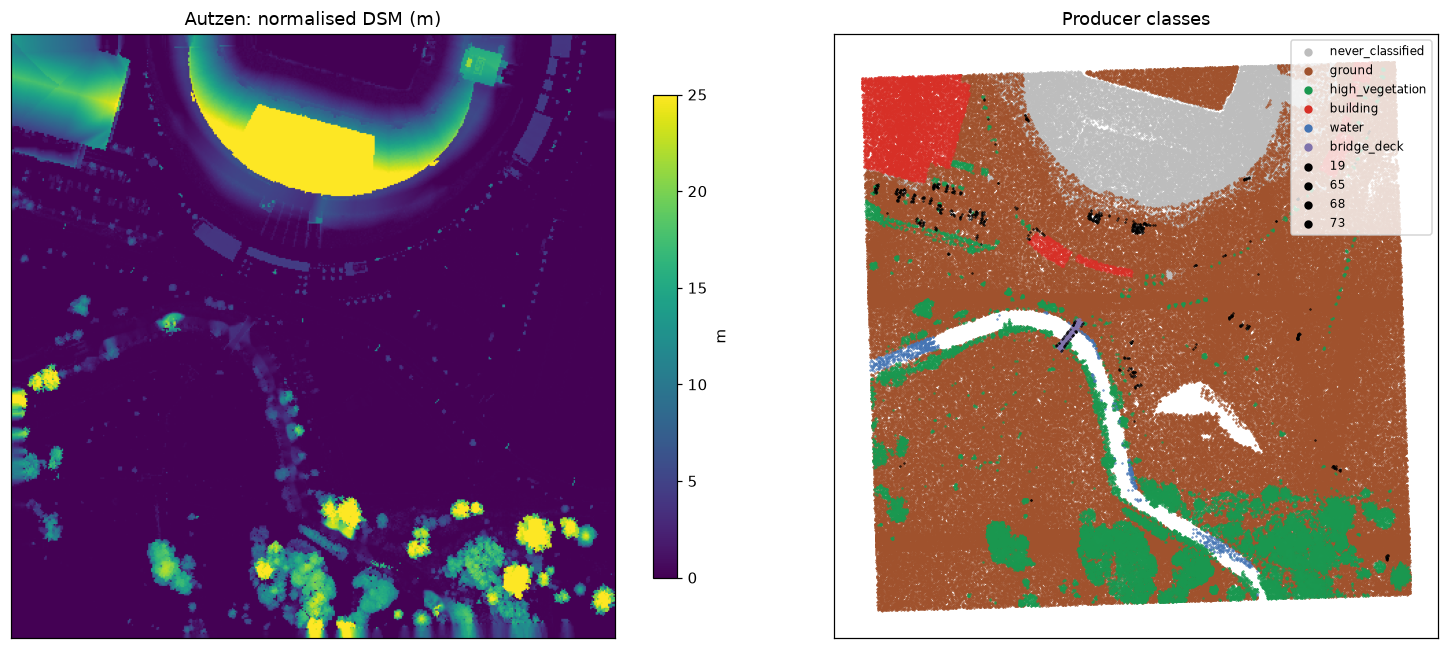

In [3]:
autzen = rs.lidar.read_las(AUTZEN).drop_noise()  # the labelled window without noise
ref = np.asarray(autzen["classification"]).copy()  # producer classes, kept for validation
print(autzen)  # count, fields and CRS
print(pd.Series(ref).map(lambda k: ASPRS_CLASSES.get(int(k), f"user {k}")).value_counts().to_string())  # reference classes

rows, grounds = {}, {}  # one row per filter
for name, fn in (("SMRF, 100 m window", lambda: rs.lidar.smrf(autzen, cell=2.0, slope=0.15, window=100)),  # SMRF
                 ("CSF, rigidness 3", lambda: rs.lidar.csf(autzen, resolution=2.0, rigidness=3)),  # stiff cloth
                 ("PMF, 200 m window", lambda: rs.lidar.pmf(autzen, cell=2.0, max_window=200))):  # exponential windows
    t0 = time.perf_counter()  # start the timer
    grounds[name] = fn()  # classify ground
    gc = np.asarray(grounds[name]["classification"]) == 2  # predicted ground
    rows[name] = {"building points put in ground": np.mean(gc[ref == 6]),  # roof absorbed into the terrain
                  "ground agreement with producer": np.mean(gc == (ref == 2)), "seconds": time.perf_counter() - t0}
display(pd.DataFrame(rows).T.round(3))  # comparison

t0 = time.perf_counter()  # start the timer
ag = grounds["PMF, 200 m window"]  # the filter that keeps the big roof off the ground
adem = rs.lidar.dem(ag, 1.0)  # DEM
adsm = rs.lidar.dsm(ag, 1.0, bounds=ag.bbox).reindex_like(adem, method="nearest")  # DSM on the same grid
andsm = rs.lidar.chm(adsm, adem, pit_free=False)  # normalised DSM (heights of all objects)
agn = rs.lidar.normalize_heights(ag, adem)  # per-point height above ground
print(f"surfaces in {time.perf_counter() - t0:.1f} s")  # timing

fig, axes = plt.subplots(1, 2, figsize=(14, 6))  # two panels
rs.viz.plot_raster(andsm, ax=axes[0], cmap="viridis", vmin=0, vmax=25, title="Autzen: normalised DSM (m)")  # nDSM
rs.lidar.plot_classification(autzen, ax=axes[1], s=0.2)  # producer classes
axes[1].set_title("Producer classes")  # title
for a in axes: a.set_xticks([]); a.set_yticks([])  # no ticks
plt.tight_layout(); plt.show()  # draw

SMRF with a 100 m window puts about 70 % of the producer's building points into the ground class, and the stiff cloth of CSF about 43 %: the largest roof is wide and flat, so to these filters it looks like a raised terrace. PMF grows its window exponentially up to 200 m, keeps 94 % of the building points out of the ground, agrees best with the producer's ground class overall and runs in a fraction of a second. The rest of the notebook uses the PMF ground.


## Eigenvalue features of roofs and trees

`rs.lidar.eigen_features` computes the covariance features of every point's `k` nearest neighbours. The histograms compare points the producer labelled as building (6) with high vegetation (5): roofs are planar with near-zero scattering, crowns scatter.


eigen features for 299,080 points in 3.2 s


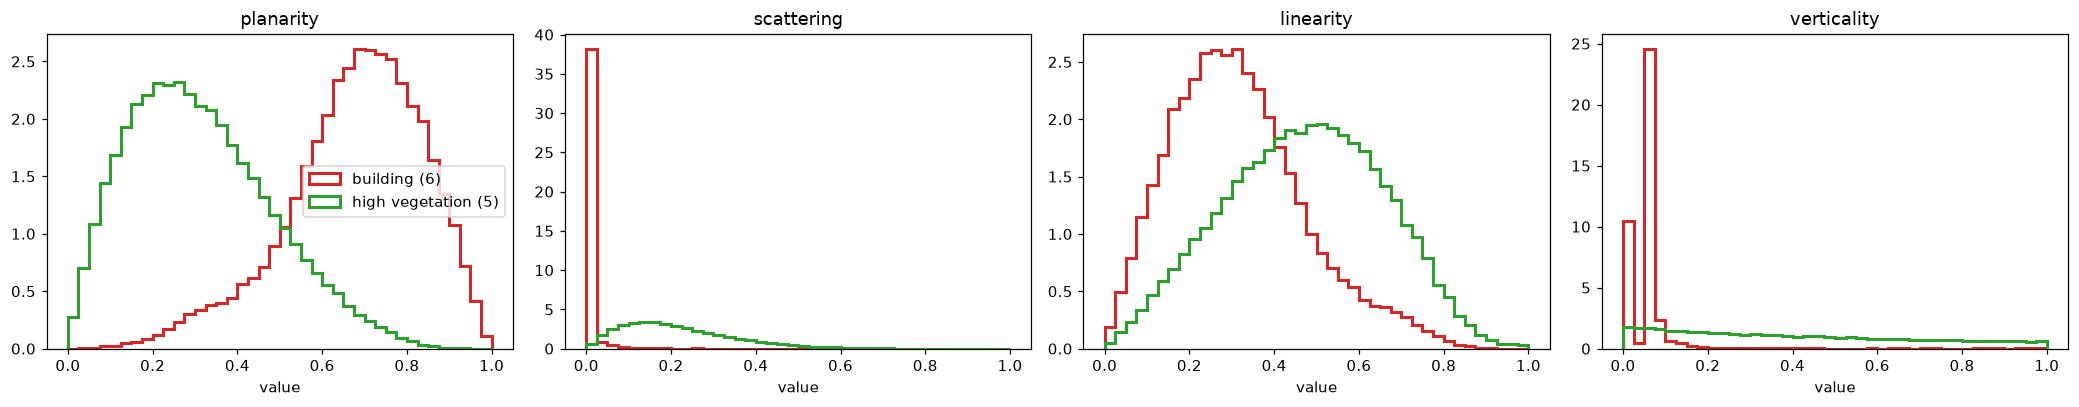

In [4]:
t0 = time.perf_counter()  # start the timer
above = agn.filter(np.asarray(agn["height"]) > 2)  # points more than 2 m above ground
ref_above = ref[np.asarray(agn["height"]) > 2]  # their producer classes
ef = rs.lidar.eigen_features(above, k=16, features=("linearity", "planarity", "scattering", "verticality"))  # features
print(f"eigen features for {len(above):,} points in {time.perf_counter() - t0:.1f} s")  # timing

fig, axes = plt.subplots(1, 4, figsize=(19, 3.8))  # four panels
for ax, f in zip(axes, ("planarity", "scattering", "linearity", "verticality")):  # each feature
    v = np.asarray(ef[f])  # values
    for cls, col, lab in ((6, "C3", "building (6)"), (5, "C2", "high vegetation (5)")):  # two classes
        # histogram of this class
        ax.hist(v[ref_above == cls], bins=np.linspace(0, 1, 41), density=True, histtype="step", lw=2, color=col, label=lab)
    ax.set(title=f, xlabel="value")  # labels
axes[0].legend(); plt.tight_layout(); plt.show()  # draw

## Classifying buildings from geometry

`rs.lidar.classify_buildings` uses these features and object-level RANSAC tests: points at least 2.5 m above ground with low scattering and linearity are roof candidates; candidates are clustered; a cluster is a building when up to six planes no steeper than 60° explain at least 80 % of its points; accepted roofs then grow to adjacent points (edges, walls), and all other above-ground points become vegetation by height. The result is compared point by point with the producer's building class.


In [5]:
def binary_scores(pred, truth):  # precision, recall, F1 and IoU of two boolean masks
    tp = np.sum(pred & truth); fp = np.sum(pred & ~truth); fn = np.sum(~pred & truth)  # counts
    return {"precision": tp / max(tp + fp, 1), "recall": tp / max(tp + fn, 1),  # scores
            "F1": 2 * tp / max(2 * tp + fp + fn, 1), "IoU": tp / max(tp + fp + fn, 1)}

t0 = time.perf_counter()  # start the timer
bld = rs.lidar.classify_buildings(ag, dtm=adem, min_height=2.5)  # buildings (6) and vegetation (3/4/5)
sec = time.perf_counter() - t0  # time taken
cb = np.asarray(bld["classification"])  # new classes
print(f"classify_buildings in {sec:.1f} s")  # timing
scores_pts = {"geometry (classify_buildings)": binary_scores(cb == 6, ref == 6)}  # point-level scores
display(pd.DataFrame(scores_pts).T.round(3))  # show them
pd.crosstab(pd.Series(ref).map(lambda k: ASPRS_CLASSES.get(int(k), f"user {k}")).rename("producer"),  # confusion table
            pd.Series(cb).map(lambda k: ASPRS_CLASSES.get(int(k), k)).rename("classify_buildings"))

classify_buildings in 4.4 s


,precision,recall,F1,IoU
geometry (classify_buildings),0.458,0.936,0.615,0.444


classify_buildings,19,65,68,73,bridge_deck,building,ground,high_vegetation,low_vegetation,medium_vegetation,never_classified,unclassified,water
producer,,,,,,,,,,,,,
bridge_deck,0,0,0,0,895,286,57,0,0,0,0,0,0
building,0,0,0,0,0,47515,3268,0,0,0,0,0,0
ground,0,0,0,0,0,14779,951091,613,12763,3106,0,19572,0
high_vegetation,0,0,0,0,0,0,4651,110223,16183,29043,0,0,0
never_classified,0,0,0,0,0,40585,13725,50253,10083,12440,9386,0,0
user 19,615,0,0,0,0,564,0,0,0,0,0,0,0
user 65,0,1741,0,0,0,0,28,0,0,0,0,0,0
user 68,0,0,131,0,0,42,0,0,0,0,0,0,0
user 73,0,0,0,39,0,18,0,0,0,0,0,0,0


## A raster rule as a baseline

A simple label-free rule on 1 m rasters: cells of the normalised DSM higher than 2.5 m where fewer than 15 % of the returns come from multi-return pulses, cleaned with a morphological opening. Comparing it with the producer's building mask at the raster level shows what the point-based geometry adds.


,precision,recall,F1,IoU
raster rule,0.271,0.837,0.409,0.257
geometry (classify_buildings),0.419,0.951,0.582,0.410


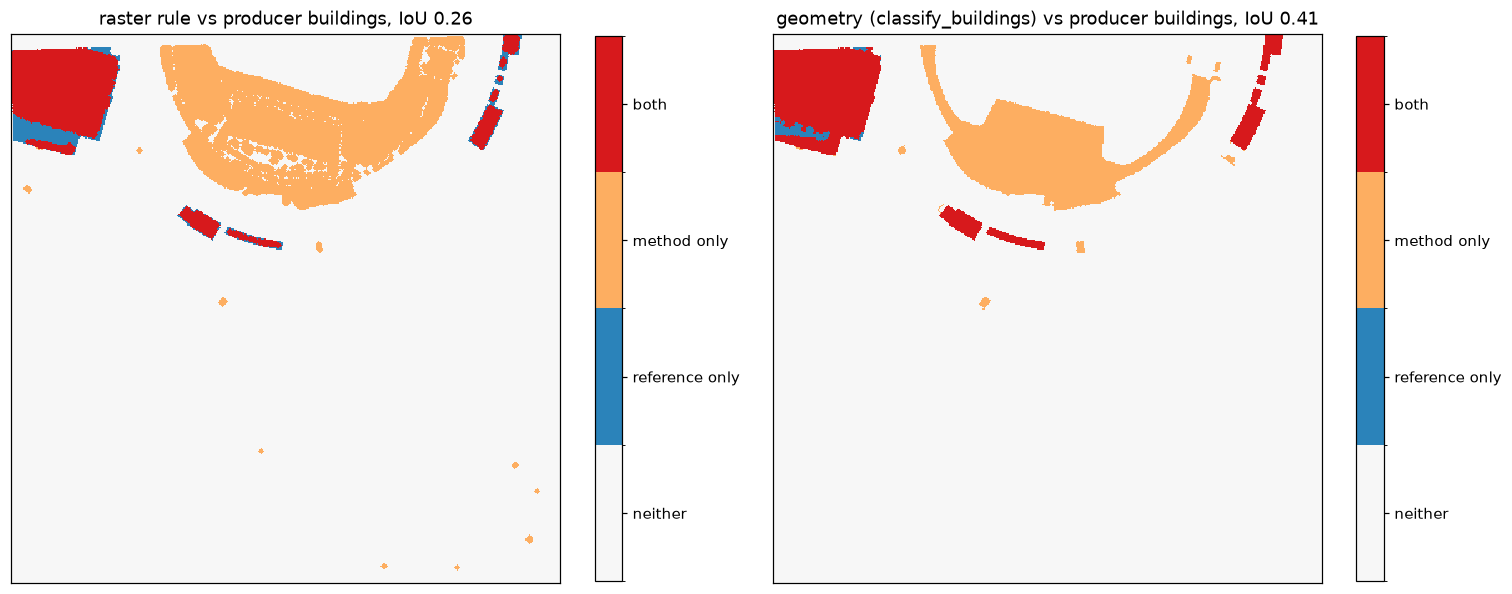

In [6]:
from scipy import ndimage as nd  # morphology
# returns from multi-return pulses per cell
multi = rs.lidar.rasterize(autzen.filter(np.asarray(autzen["number_of_returns"]) > 1), 1.0, stat="count",
                           bounds=autzen.bbox).reindex_like(adem, method="nearest").fillna(0)  # multi-return points
allr = rs.lidar.rasterize(autzen, 1.0, stat="count", bounds=autzen.bbox).reindex_like(adem, method="nearest")  # all points
rule = ((andsm > 2.5) & (multi / allr < 0.15)).values  # tall and mostly single return
rule = nd.binary_opening(rule, iterations=2)  # remove small specks

def mask_of(cls_array, cloud, code=6):  # 1 m raster mask of points with a class code
    m = rs.lidar.rasterize(cloud.filter(cls_array == code), 1.0, stat="count", bounds=autzen.bbox)  # count per cell
    return nd.binary_closing(m.reindex_like(adem, method="nearest").fillna(0).values > 0, iterations=1)  # closed mask

ref_mask = mask_of(ref, autzen)  # producer buildings
geo_mask = mask_of(cb, bld)  # classify_buildings result
masks = {"raster rule": rule, "geometry (classify_buildings)": geo_mask}  # the two methods
display(pd.DataFrame({k: binary_scores(m, ref_mask) for k, m in masks.items()}).T.round(3))  # raster-level scores

fig, axes = plt.subplots(1, 2, figsize=(14, 6.5))  # two panels
cat = {0: ("neither", "#f7f7f7"), 1: ("reference only", "#2b83ba"), 2: ("method only", "#fdae61"), 3: ("both", "#d7191c")}  # legend
for ax, (name, m) in zip(axes, masks.items()):  # each method
    cmp = adem.copy(data=(m.astype(int) * 2 + ref_mask.astype(int)))  # comparison codes
    iou = binary_scores(m, ref_mask)["IoU"]  # IoU
    rs.viz.plot_raster(cmp, ax=ax, categorical=cat, title=f"{name} vs producer buildings, IoU {iou:.2f}")  # map
    ax.set_xticks([]); ax.set_yticks([])  # no ticks
plt.tight_layout(); plt.show()  # draw

Both methods find almost all of the producer's buildings (recall 0.84 for the raster rule, 0.95 for `classify_buildings`), but their precision is low, and the maps show why. Most of the "method only" area is the stadium bowl, which the producer did not label as a building although both methods find it: a **reference** error rather than a method error. The remaining differences are method errors: dense tree crowns with flat tops pass the raster rule as small specks, and the geometric method also takes in the flat field inside the stadium, which sits on the stands. The point-based geometry is clearly better (IoU 0.41 against 0.26). Low agreement can mean an imperfect method, imperfect labels or both, so disagreements should be inspected before trusting either.


## Building footprints and heights

`rs.lidar.building_footprints` rasterises the building points, closes small gaps, vectorises the mask into polygons, removes slivers smaller than `min_area` and adds the area, the height (95th percentile of roof heights above the DEM) and the number of points of each building. Matching the footprints from `classify_buildings` to those from the producer labels gives a per-building comparison.


In [7]:
ref_cloud = rs.lidar.normalize_heights(autzen.with_field("classification", ref.astype("uint8")), adem)  # producer labels + heights
fp_ref = rs.lidar.building_footprints(ref_cloud, res=1.0, min_area=30, dtm=adem)  # reference footprints
fp_geo = rs.lidar.building_footprints(rs.lidar.normalize_heights(bld, adem), res=1.0, min_area=30, dtm=adem)  # extracted
print(f"reference footprints: {len(fp_ref)} | extracted: {len(fp_geo)}")  # counts

# overlaps between reference and extracted footprints
inter = gpd.overlay(fp_ref[["geometry"]].reset_index(names="ref_id"), fp_geo[["geometry"]].reset_index(names="geo_id"),
                    how="intersection")  # overlaps between the two sets
inter["a"] = inter.area  # overlap area
best = inter.sort_values("a").groupby("ref_id").last()  # best-matching extracted footprint per reference building
match = fp_ref[["area_m2", "height_m"]].join(best[["geo_id", "a"]])  # reference attributes plus match
match["IoU"] = [row.a / (row.area_m2 + fp_geo.area[int(row.geo_id)] - row.a) if pd.notnull(row.geo_id) else 0  # polygon IoU
                for row in match.itertuples()]
match["height extracted (m)"] = [fp_geo.height_m[int(g)] if pd.notnull(g) else np.nan for g in match.geo_id]  # height
match.sort_values("area_m2", ascending=False).head(10).drop(columns="a").round(2)  # largest reference buildings

reference footprints: 6 | extracted: 12


,area_m2,height_m,geo_id,IoU,height extracted (m)
1,6116.0,19.32,2,0.93,19.52
3,592.0,4.43,5,0.99,4.43
4,478.0,3.97,8,1.00,3.97
0,310.0,4.45,0,1.00,4.45
5,300.0,4.51,9,1.00,4.51
2,47.0,4.50,4,1.00,4.49


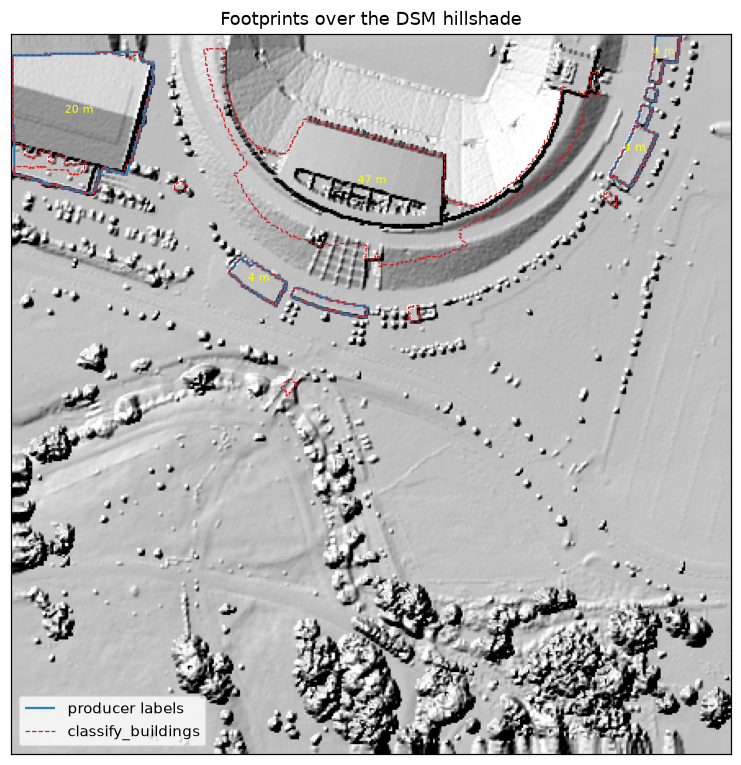

In [8]:
fig, ax = plt.subplots(figsize=(9, 8.5))  # one panel
rs.viz.plot_raster(rs.lidar.hillshade(adsm), ax=ax, cmap="gray", colorbar=False, title="Footprints over the DSM hillshade")  # relief
fp_ref.boundary.plot(ax=ax, color="#2b83ba", lw=1.5, label="producer labels")  # reference outlines
fp_geo.boundary.plot(ax=ax, color="#d7191c", lw=0.8, ls="--", label="classify_buildings")  # extracted outlines
for _, r in fp_geo.iterrows():  # each extracted building
    if r.area_m2 > 300:  # label the larger ones
        # label
        ax.text(r.geometry.centroid.x, r.geometry.centroid.y, f"{r.height_m:.0f} m", fontsize=7, color="yellow", ha="center")
ax.legend(loc="lower left"); ax.set_xticks([]); ax.set_yticks([]); plt.show()  # draw

## Roof planes

`rs.lidar.segment_roof_planes` extracts planes one after another with RANSAC from the points of one building and splits each plane's inliers into connected patches. Each plane gets a slope and an aspect, the inputs for LoD2 roof models and for solar analysis. The cell segments the largest building found.


,slope_deg,aspect_deg,n_points
0,0.1,357.0,10538
1,3.8,115.1,7644
2,2.3,275.4,5007
3,2.3,275.4,1097
4,0.9,142.0,3656
5,0.9,142.0,789
6,3.5,349.6,2821
7,3.5,349.6,194
8,3.6,37.0,2419
9,3.6,37.0,111


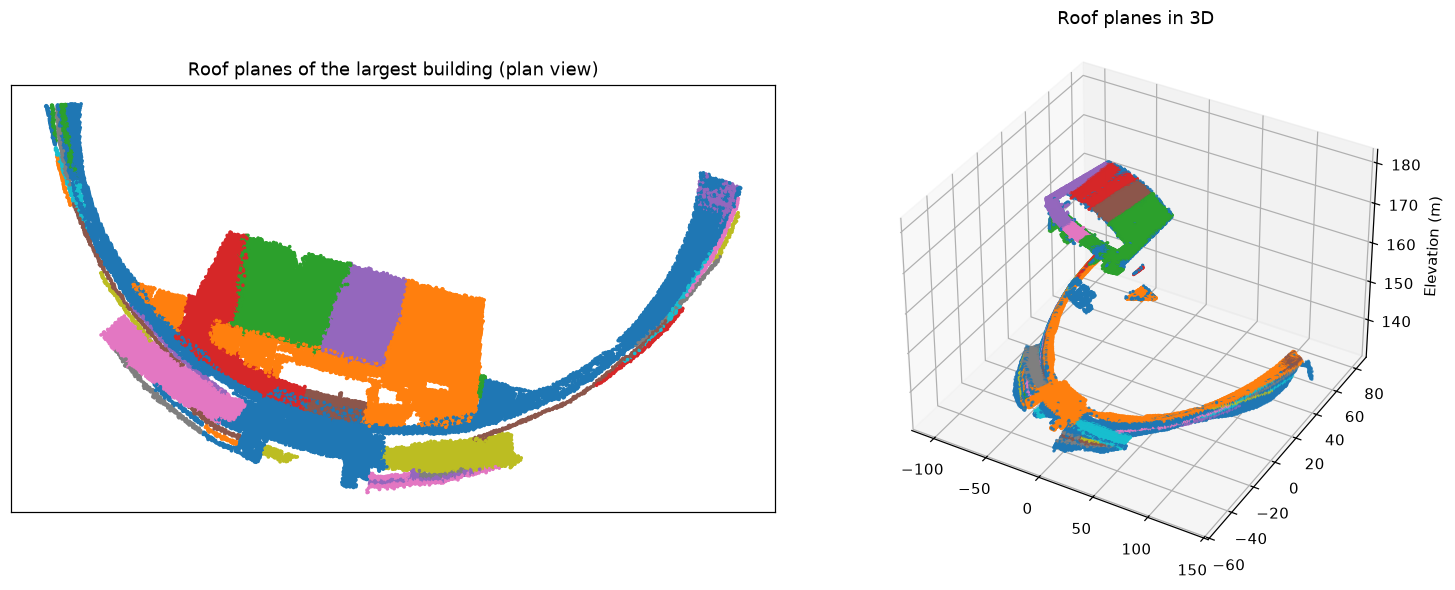

In [9]:
b_pts = bld.filter(cb == 6)  # building points
labels_b = rs.lidar.euclidean_clusters(b_pts, radius=1.5, min_points=50, dims=2)  # one cluster per building
big = b_pts.filter(labels_b == 0)  # the largest building (cluster 0)
planes_pc, planes = rs.lidar.segment_roof_planes(big, distance=0.15, min_points=40, max_planes=12)  # RANSAC planes
display(planes[["slope_deg", "aspect_deg", "n_points"]].round(1))  # one row per plane

pid = np.asarray(planes_pc["plane_id"])  # plane of each point
fig = plt.figure(figsize=(14, 5.5))  # two panels
ax1 = fig.add_subplot(1, 2, 1)  # plan view
ax1.scatter(big.x, big.y, c=np.where(pid >= 0, pid % 10, np.nan), cmap="tab10", s=2)  # points by plane
ax1.set(title="Roof planes of the largest building (plan view)", aspect="equal", xticks=[], yticks=[])  # labels
ax2 = fig.add_subplot(1, 2, 2, projection="3d")  # 3D view
ax2.scatter(big.x - big.x.mean(), big.y - big.y.mean(), big.z, c=np.where(pid >= 0, pid % 10, -1), cmap="tab10", s=1)  # 3D
ax2.set(title="Roof planes in 3D", zlabel="Elevation (m)"); ax2.view_init(35, -60)  # labels and angle
plt.tight_layout(); plt.show()  # draw

## Roof solar potential

`rs.lidar.solar_potential` averages the cosine of the solar incidence angle over a set of sun positions (here every hour from 6:00 to 18:00 solar time on one day per month at 44° N), optionally with cast shadows traced along each sun direction across the DSM. Values are relative (1 = a surface facing the sun at every position). With footprints it reports the mean value per roof and the area that is both well lit and not too steep.


solar potential in 14.3 s


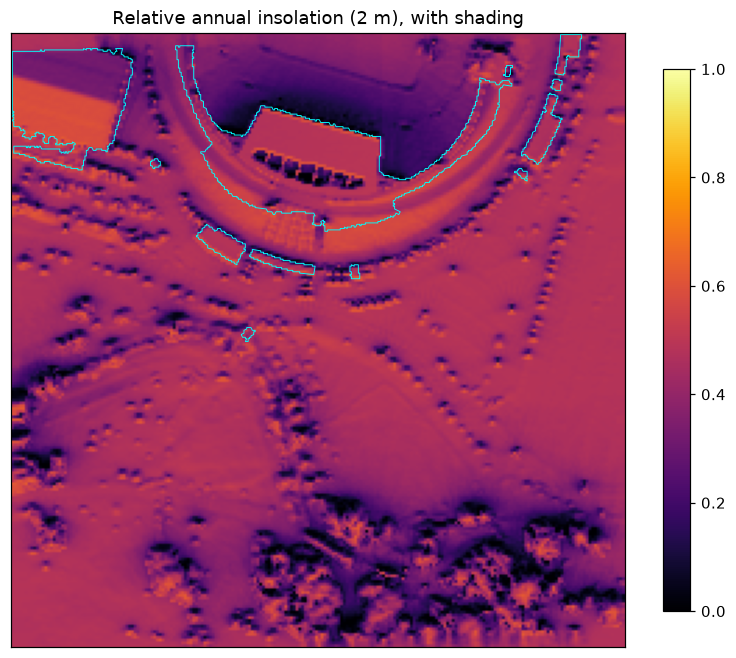

,building_id,area_m2,z_max,n_points,height_m,solar_mean,suitable_area_m2
1,2,10078.0,179.96,55017,47.28,0.43,6536.0
2,3,5739.0,155.47,38329,19.52,0.46,3112.0
5,7,595.0,134.85,3017,4.43,0.45,444.0
8,17,479.0,133.83,2432,3.97,0.48,412.0
0,1,310.0,135.40,2023,4.45,0.45,232.0
9,21,300.0,134.49,1530,4.51,0.43,184.0
10,22,58.0,133.82,312,3.97,0.45,40.0
11,23,51.0,131.12,328,3.37,0.45,28.0


In [10]:
t0 = time.perf_counter()  # start the timer
dsm2 = adsm.coarsen(x=2, y=2, boundary="trim").max().rio.write_crs(adsm.rio.crs)  # 2 m DSM keeps the run short
# relative insolation with shading
solar = rs.lidar.solar_potential(dsm2, latitude=44.05, days=np.arange(15, 365, 30), hours=np.arange(6, 19),
                                 shading=True)  # relative insolation with shadows
# summary per roof
roofs = rs.lidar.solar_potential(dsm2, latitude=44.05, days=np.arange(15, 365, 30), hours=np.arange(6, 19),
                                 footprints=fp_geo, shading=True)  # per-roof summary
print(f"solar potential in {time.perf_counter() - t0:.1f} s")  # timing

fig, ax = plt.subplots(figsize=(9, 8))  # one panel
rs.viz.plot_raster(solar, ax=ax, cmap="inferno", vmin=0, vmax=1, title="Relative annual insolation (2 m), with shading")  # map
fp_geo.boundary.plot(ax=ax, color="cyan", lw=0.6)  # roof outlines
ax.set_xticks([]); ax.set_yticks([]); plt.show()  # draw
roofs.drop(columns="geometry").sort_values("suitable_area_m2", ascending=False).head(8).round(2)  # best roofs

## Wires and other linear objects

Power lines are thin, elevated and strongly linear. `rs.lidar.detect_power_lines` keeps points at least 5 m above ground with linearity above 0.85, clusters them and keeps clusters longer than 15 m as wires (ASPRS class 14). At 7 points/m² wires are only partly sampled, so the detections are fragments; dedicated corridor surveys from helicopters reach hundreds of points per m².


2 linear objects longer than 15 m in 2.4 s


,length_m,height_m,n_points
0,24.2,18.0,52
1,23.9,17.0,47


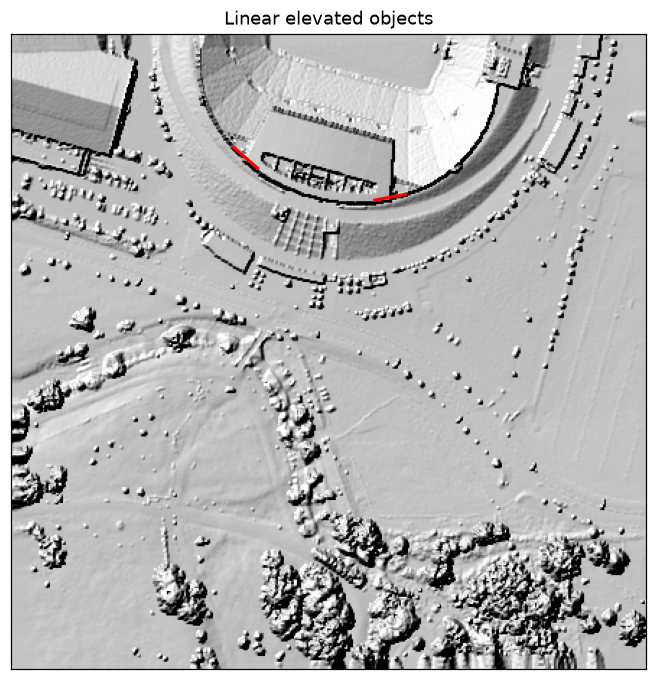

In [11]:
t0 = time.perf_counter()  # start the timer
wires_pc, wires = rs.lidar.detect_power_lines(agn, dtm=adem, min_height=5, linearity=0.85, min_length=15)  # wire candidates
print(f"{len(wires)} linear objects longer than 15 m in {time.perf_counter() - t0:.1f} s")  # result
if len(wires):  # anything found
    display(wires.drop(columns="geometry").round(1).head(10))  # their length and height
    fig, ax = plt.subplots(figsize=(8, 7.5))  # one panel
    rs.viz.plot_raster(rs.lidar.hillshade(adsm), ax=ax, cmap="gray", colorbar=False, title="Linear elevated objects")  # relief
    wires.plot(ax=ax, color="red", lw=2); ax.set_xticks([]); ax.set_yticks([]); plt.show()  # draw

## Buildings on the UB campus without labels

The 2008 UB survey has about 1 point/m² and only ground classified, so the label-free workflow is the only option. The two tiles are reprojected to UTM zone 17N; the analysis uses the same 1 km block as the processing notebook; ground is reclassified with PMF and windows up to 120 m on a 2 m grid (the campus buildings are large), and `classify_buildings` then separates buildings from trees. With only one or two points per m², plane tests need lower point counts per cluster.


UB: 1,028,848 points | 48 buildings, 6.1 ha of roof | 24 s


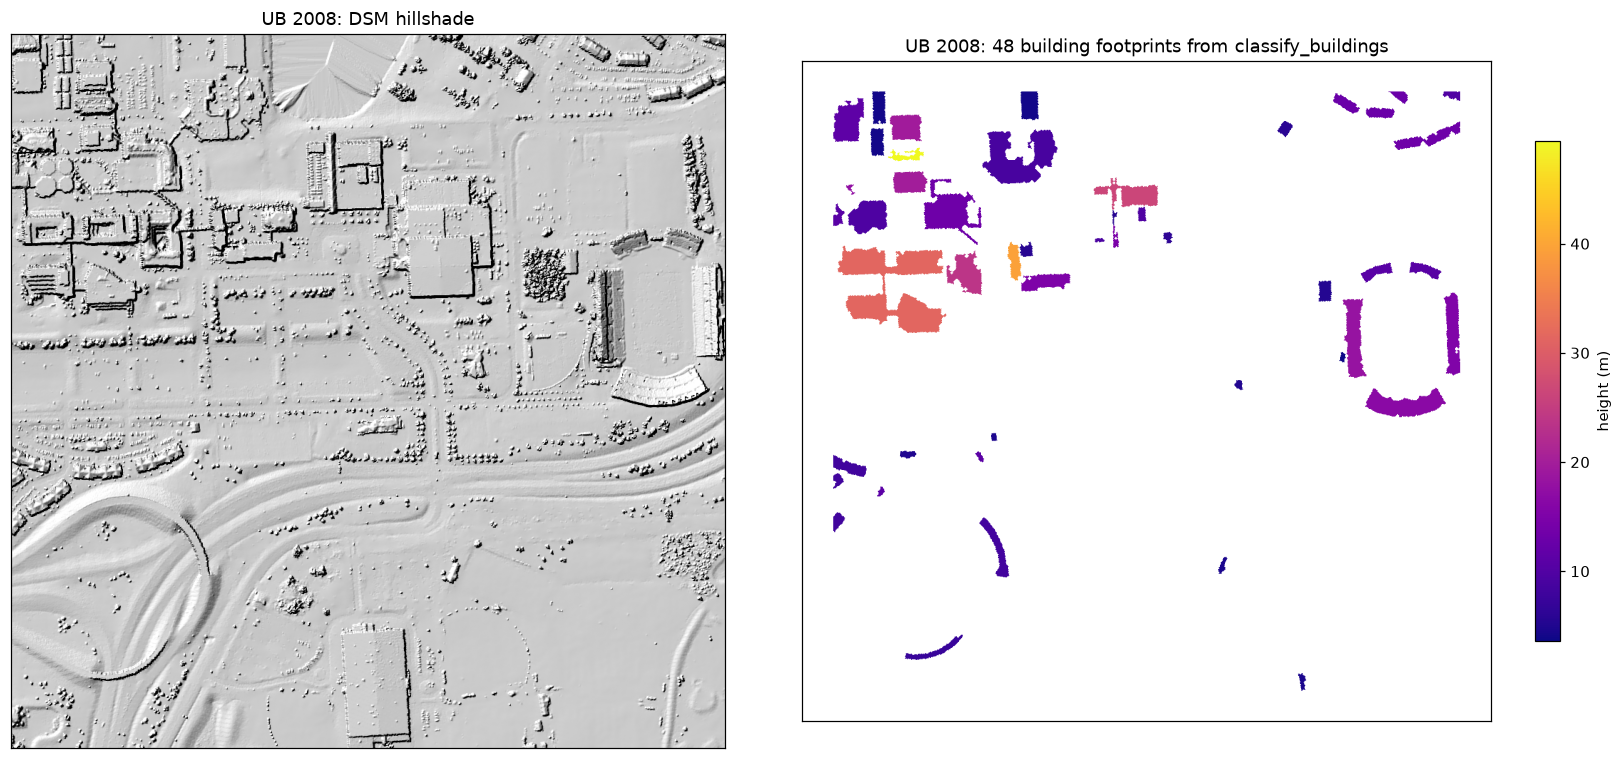

,building_id,area_m2,z_max,n_points,height_m
count,48.0,48.0,48.0,48.0,48.0
mean,92.8,1278.9,193.9,1005.4,12.4
50%,89.5,627.0,192.0,470.0,10.3
max,194.0,11452.0,227.8,7133.0,49.4


In [12]:
ub = rs.lidar.reproject(rs.lidar.merge_pointclouds([rs.lidar.read_las(p) for p in UB_TILES]), 26917).drop_noise()  # metres
ucx, ucy = np.mean(ub.bbox[::2]), np.mean(ub.bbox[1::2])  # centre of the two tiles
ub = ub.crop(ucx - 500, ucy - 500, ucx + 500, ucy + 500)  # a 1 km x 1 km block of the campus
t0 = time.perf_counter()  # start the timer
ubg = rs.lidar.pmf(ub, cell=2.0, max_window=120)  # ground with PMF, wide windows
udem = rs.lidar.dem(ubg, 1.0)  # DEM
ubn = rs.lidar.normalize_heights(ubg, udem)  # heights above ground
ubb = rs.lidar.classify_buildings(ubg, dtm=udem, min_height=3.0, min_points=15, cluster_radius=2.5, k=12)  # buildings
# UB footprints with heights
fp_ub = rs.lidar.building_footprints(rs.lidar.normalize_heights(ubb, udem), res=1.0, min_area=80, dtm=udem,
                                     close_iter=2)  # footprints
# summary line
print(f"UB: {len(ub):,} points | {len(fp_ub)} buildings, {fp_ub.area_m2.sum() / 1e4:.1f} ha of roof | "
      f"{time.perf_counter() - t0:.0f} s")  # summary

udsm = rs.lidar.dsm(ubg, 1.0, bounds=ubg.bbox).reindex_like(udem, method="nearest")  # DSM
fig, axes = plt.subplots(1, 2, figsize=(16, 7))  # two panels
rs.viz.plot_raster(rs.lidar.hillshade(udsm), ax=axes[0], cmap="gray", colorbar=False, title="UB 2008: DSM hillshade")  # relief
# footprints coloured by height
fp_ub.plot(ax=axes[1], column="height_m", cmap="plasma", legend=True, legend_kwds={"label": "height (m)", "shrink": 0.7})
axes[1].set(title=f"UB 2008: {len(fp_ub)} building footprints from classify_buildings", aspect="equal")  # title
for a in axes: a.set_xticks([]); a.set_yticks([])  # no ticks
plt.tight_layout(); plt.show()  # draw
fp_ub.drop(columns="geometry").describe().loc[["count", "mean", "50%", "max"]].round(1)  # summary statistics

With only one or two points per m² and almost no multiple returns (see the processing notebook), the label-free workflow finds most of the campus buildings, including the tall residence and academic blocks in the north-west and the stands around the stadium. Its errors are instructive. Curved highway ramps and bridge decks in the south are elevated, planar and single-return, so they pass the building test; a road layer or a height-above-road rule would remove them. Some large flat roofs in the centre are missed, because the sparse roof points are not grouped into large enough clusters. Older, sparse surveys need lower thresholds and more checking than modern dense ones.


## An LoD1 block model

An LoD1 model extrudes each footprint to its height. Drawing the footprints as prisms on top of the terrain gives a simple 3D view of the campus.


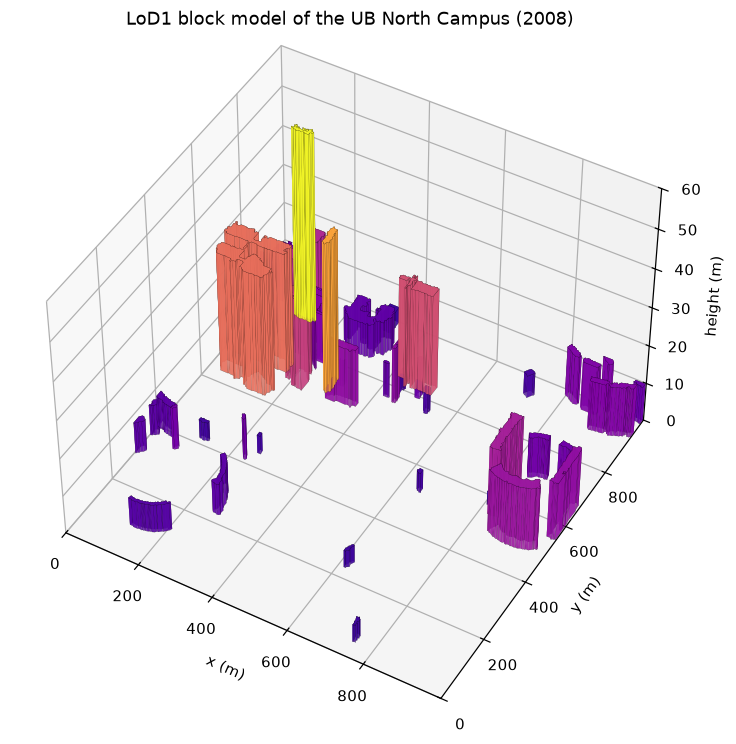

In [13]:
fig = plt.figure(figsize=(12, 8)); ax = fig.add_subplot(projection="3d")  # 3D axes
ox, oy = ub.bbox[0], ub.bbox[1]  # local origin for readable axes
base_z = float(np.nanmedian(udem.values))  # a common base height
for _, r in fp_ub.iterrows():  # each building
    geom = r.geometry.simplify(1.0)  # simplified outline
    polys = list(geom.geoms) if geom.geom_type == "MultiPolygon" else [geom]  # its parts
    for p in polys:  # each part
        xs, ys = np.asarray(p.exterior.xy)  # outline coordinates
        xs, ys = xs - ox, ys - oy  # local coordinates
        top = [list(zip(xs, ys, np.full(len(xs), r.height_m)))]  # roof polygon
        # one wall per outline segment
        walls = [[(xs[i], ys[i], 0), (xs[i + 1], ys[i + 1], 0), (xs[i + 1], ys[i + 1], r.height_m), (xs[i], ys[i], r.height_m)]
                 for i in range(len(xs) - 1)]  # wall quadrilaterals
        col = plt.cm.plasma(min(float(r.height_m) / 50.0, 1.0))  # colour by height (float in 0 to 1)
        ax.add_collection3d(Poly3DCollection(top + walls, facecolor=col, edgecolor="k", linewidth=0.1, alpha=0.9))  # prism
# axes and title
ax.set(xlim=(0, ub.bbox[2] - ox), ylim=(0, ub.bbox[3] - oy), zlim=(0, 60), xlabel="x (m)", ylabel="y (m)",
       zlabel="height (m)", title="LoD1 block model of the UB North Campus (2008)")  # axes
ax.view_init(45, -60); plt.show()  # draw

## Exporting the products


In [14]:
gpkg = OUT / "urban_buildings.gpkg"  # vector output
fp_ref.to_file(gpkg, layer="autzen_reference", driver="GPKG")  # reference footprints
fp_geo.to_file(gpkg, layer="autzen_extracted", driver="GPKG")  # extracted footprints
roofs.to_file(gpkg, layer="autzen_roof_solar", driver="GPKG")  # roofs with solar potential
fp_ub.to_file(gpkg, layer="ub_buildings", driver="GPKG")  # UB footprints
if len(wires):  # wires, if any
    wires.to_file(gpkg, layer="autzen_wires", driver="GPKG")  # wire lines
rs.write(andsm.astype("float32"), OUT / "autzen_ndsm_1m.tif")  # normalised DSM
rs.write(solar.astype("float32"), OUT / "autzen_solar_2m.tif")  # solar potential
rs.lidar.write_las(ubb, OUT / "ub_buildings_classified.laz")  # UB with buildings and vegetation classes
for p in (gpkg, OUT / "autzen_ndsm_1m.tif", OUT / "autzen_solar_2m.tif", OUT / "ub_buildings_classified.laz"):  # list
    print(f"{p.name:30s} {p.stat().st_size / 1e6:6.1f} MB")  # name and size

urban_buildings.gpkg              0.4 MB
autzen_ndsm_1m.tif                0.5 MB
autzen_solar_2m.tif               0.2 MB
ub_buildings_classified.laz       3.7 MB


## Summary and exercises

**Key points**

- The ground filter's window must exceed the widest roof, or large buildings vanish into the terrain.
- Roofs are planar and mostly single-return; crowns scatter and return several echoes. Eigenvalue features capture this at each point.
- `classify_buildings` combines local planarity with object-level RANSAC tests; a raster rule on nDSM height and return structure is a quick baseline.
- Validate with precision, recall and IoU, and inspect disagreements: reference labels are not always complete.
- Footprints carry area and height; RANSAC roof planes give slope and aspect for LoD2 models and solar analysis.
- Linearity finds wires, but sparse airborne data sample them only in fragments.
- The same workflow runs on older, sparser surveys without labels, with smaller minimum cluster sizes.

**`geolattice.rsense` functions used:** `rs.lidar.read_las`, `rs.lidar.reproject`, `rs.lidar.merge_pointclouds`, `rs.lidar.smrf`, `rs.lidar.csf`, `rs.lidar.pmf`, `rs.lidar.dem`, `rs.lidar.dsm`, `rs.lidar.chm`, `rs.lidar.normalize_heights`, `rs.lidar.eigen_features`, `rs.lidar.classify_buildings`, `rs.lidar.rasterize`, `rs.lidar.building_footprints`, `rs.lidar.euclidean_clusters`, `rs.lidar.segment_roof_planes`, `rs.lidar.solar_potential`, `rs.lidar.detect_power_lines`, `rs.lidar.plot_classification`, `rs.lidar.hillshade`, `rs.lidar.write_las`, `rs.write`, `rs.viz.plot_raster`.

**Exercises**

1. Run PMF on Autzen with `max_window` of 30, 60, 120 and 200 m and compute the building IoU of `classify_buildings` for each. Why does it change?
2. Vary `max_scattering` (0.02 to 0.1) and `plane_fraction` (0.6 to 0.9). Which setting gives the best F1?
3. Plot roof-plane aspect against solar potential for the planes of the largest building.
4. Compute solar potential without shading and map the difference. Which roofs are shaded most by trees or neighbours?
5. On the UB campus, compare footprint areas from 1 m and 2 m rasters. How sensitive is roof area to the cell size at 1 point/m²?
